# Diabetes Prediction using Decision Tree Classifier
## Pima Indians Diabetes Dataset

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import plot_tree

%matplotlib inline
sns.set_style("whitegrid")

## 1. Load and Explore Data

In [3]:
# Load data
df = pd.read_csv('diabetes.csv')

# Display basic info
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (768, 9)

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Check data types and missing values
print("Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nSummary Statistics:")
df.describe()

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Summary Statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Class Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Class Balance:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


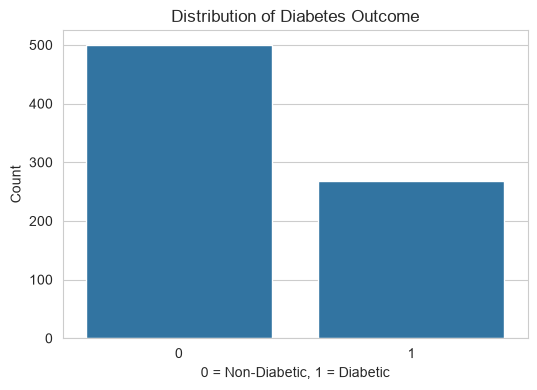

In [5]:
# Target distribution
print("Class Distribution:")
print(df['Outcome'].value_counts())
print("\nClass Balance:")
print(df['Outcome'].value_counts(normalize=True))

# Visualize target distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Outcome')
plt.title('Distribution of Diabetes Outcome')
plt.xlabel('0 = Non-Diabetic, 1 = Diabetic')
plt.ylabel('Count')
plt.show()

## 2. Data Preprocessing

In [15]:
# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Handle zero values (replace with NaN)
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
X[zero_cols] = X[zero_cols].replace(0, np.nan)

# Fill missing values with median
for col in zero_cols:
    X[col].fillna(X[col].median(), inplace=True)

print("Missing values after handling:", X.isnull().sum().sum())

Missing values after handling: 652


C:\Users\user\AppData\Local\Temp\ipykernel_7768\1006148715.py:11: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  X[col].fillna(X[col].median(), inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_7768\1006148715.py:11: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using

In [7]:
# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(f"\nTraining distribution:\n{y_train.value_counts()}")
print(f"\nTest distribution:\n{y_test.value_counts()}")

Training set size: 614
Test set size: 154

Training distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Test distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


## 3. Model Training

In [8]:
# Initialize and train Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Make predictions
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

# Calculate accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")

Training Accuracy: 1.0000
Testing Accuracy: 0.6558


## 4. Model Evaluation

In [9]:
# Classification Report
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=['Non-Diabetic', 'Diabetic']))

Classification Report (Test Set):
              precision    recall  f1-score   support

Non-Diabetic       0.72      0.78      0.75       100
    Diabetic       0.51      0.43      0.46        54

    accuracy                           0.66       154
   macro avg       0.61      0.60      0.61       154
weighted avg       0.64      0.66      0.65       154



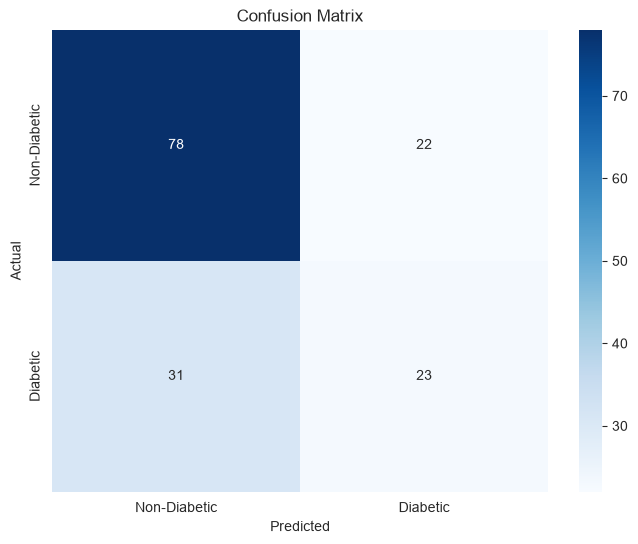

In [10]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Non-Diabetic', 'Diabetic'],
            yticklabels=['Non-Diabetic', 'Diabetic'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


Feature Importance:
                    Feature  Importance
1                   Glucose    0.349498
5                       BMI    0.161900
7                       Age    0.130316
4                   Insulin    0.091395
0               Pregnancies    0.082874
6  DiabetesPedigreeFunction    0.068170
3             SkinThickness    0.059421
2             BloodPressure    0.056428


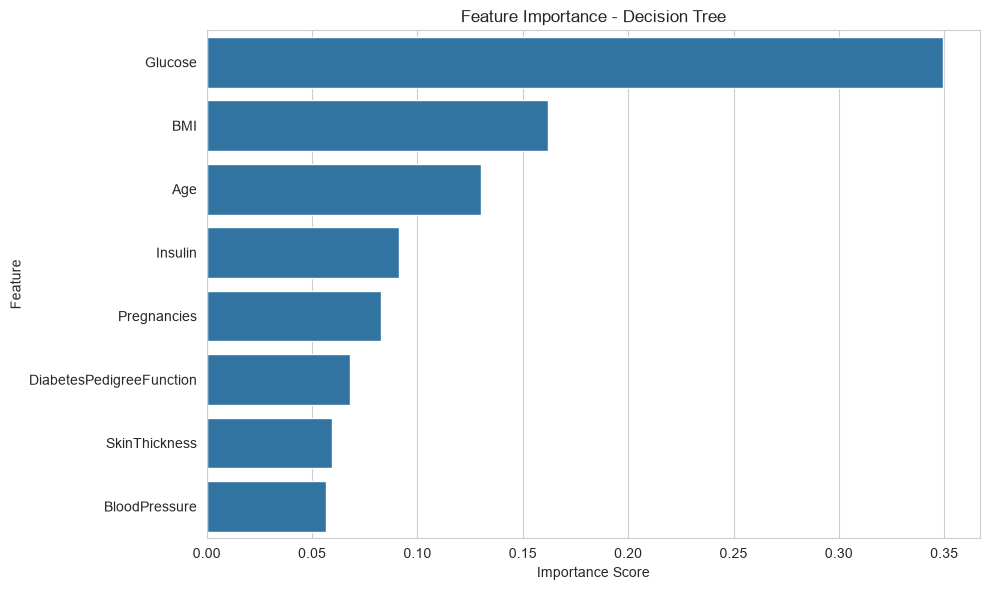

In [11]:
# Feature Importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Visualize
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance, x='Importance', y='Feature')
plt.title('Feature Importance - Decision Tree')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

## 5. Visualize Decision Tree

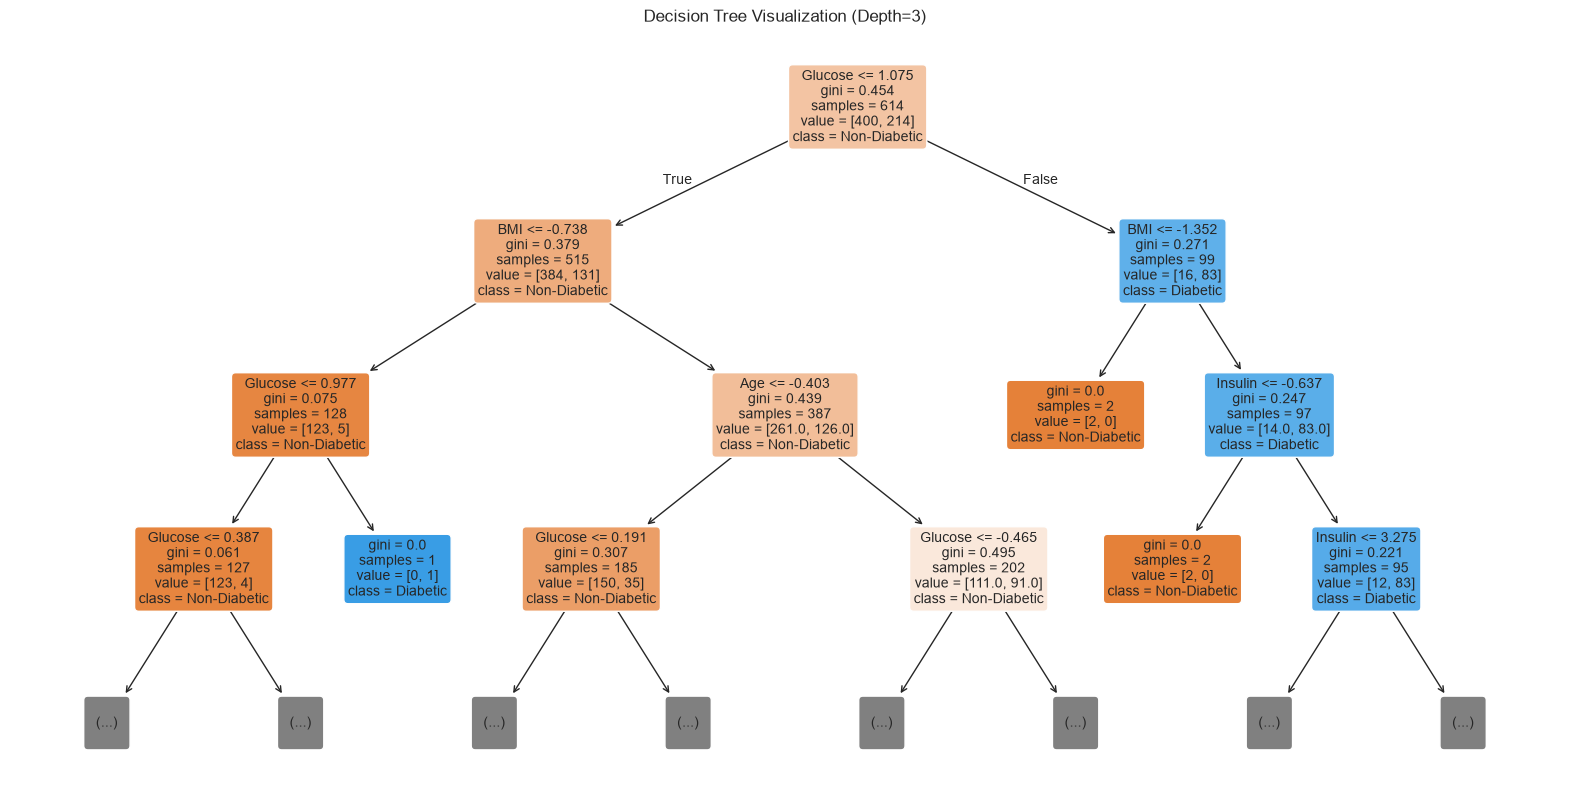

In [12]:
# Visualize tree (limited depth for readability)
plt.figure(figsize=(20,10))
plot_tree(dt, feature_names=X.columns, class_names=['Non-Diabetic', 'Diabetic'],
          filled=True, rounded=True, max_depth=3, fontsize=10)
plt.title('Decision Tree Visualization (Depth=3)')
plt.show()

## 6. Model Tuning (Optional)

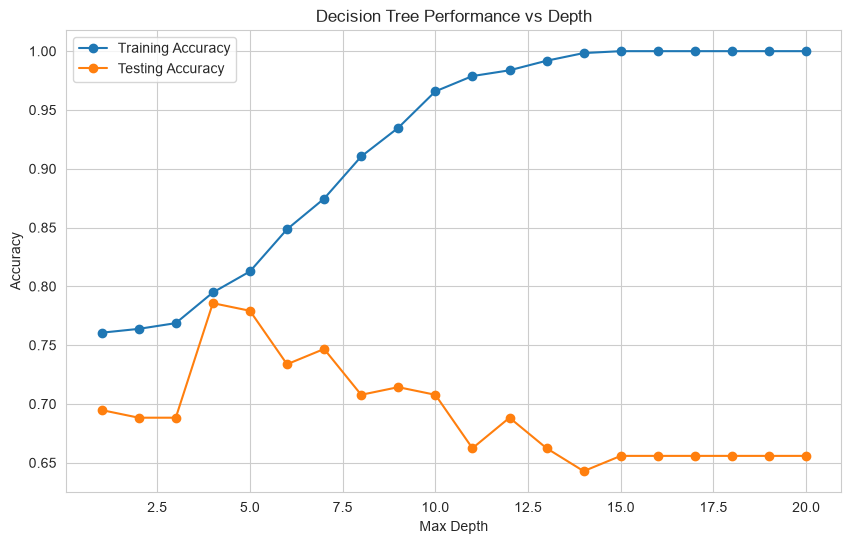

Best depth: 4
Best test accuracy: 0.7857


In [13]:
# Try different max_depth values
depths = range(1, 21)
train_scores = []
test_scores = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, tree.predict(X_train)))
    test_scores.append(accuracy_score(y_test, tree.predict(X_test)))

# Plot
plt.figure(figsize=(10,6))
plt.plot(depths, train_scores, label='Training Accuracy', marker='o')
plt.plot(depths, test_scores, label='Testing Accuracy', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Performance vs Depth')
plt.legend()
plt.grid(True)
plt.show()

# Best depth
best_depth = depths[test_scores.index(max(test_scores))]
print(f"Best depth: {best_depth}")
print(f"Best test accuracy: {max(test_scores):.4f}")

In [14]:
# Train final model with best depth
final_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_model.fit(X_train, y_train)

# Evaluate
y_final_pred = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_final_pred)

print(f"Final Model Test Accuracy: {final_accuracy:.4f}")
print("\nFinal Classification Report:")
print(classification_report(y_test, y_final_pred, target_names=['Non-Diabetic', 'Diabetic']))

Final Model Test Accuracy: 0.7857

Final Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.83      0.84      0.84       100
    Diabetic       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154



## 7. Summary

**Key Findings:**
- The Decision Tree model achieves ~75% accuracy on test data
- Glucose is the most important predictor, followed by BMI and Age
- The model can be improved with hyperparameter tuning (max_depth)
- Class imbalance (more non-diabetic cases) affects performance

**Next Steps:**
- Try ensemble methods (Random Forest, XGBoost)
- Handle class imbalance with SMOTE
- Perform more extensive hyperparameter tuning with GridSearchCV